# MS-DSA-NET: внешняя валидация на IDEAS (ds005602)

**Модель:** MS-DSA-NET (Zhang et al., 2024), веса обучены на Bonn/UHB (ds004199) — его и его копии для теста не используем.
**Тест:** IDEAS (UCL), OpenNeuro **ds005602**, T1w + FLAIR; с figshare — резекционные маски (`MaskInRawData`, нативное T1)
и метаданные (`Metadata_Release_Anon.csv`, колонка `Pathology`). Основная когорта — `Pathology == FCD` (40 пациентов).

### Что выполняется параллельно
```
 [скачивание S3] ×N_DOWNLOAD потоков ─┐
                                      ▼
 [FSL: T1→MNI ‖ FLAIR→T1] ×N_FSL_JOBS испытуемых одновременно (внутри испытуемого 2 ветки параллельно)
                                      ▼  очередь ready
 [загрузка + нормализация на CPU]  — поток-префетчер, держит PREFETCH готовых тензоров (pinned memory)
                                      ▼  очередь batch
 [GPU: sliding window 128³]        — одна GPU, SW_BATCH окон за проход (подбирается автоматически)
                                      ▼
 [запись NIfTI + метрики] ×N_WRITERS потоков
```
Испытуемый идёт на GPU сразу после своего препроцессинга, не дожидаясь остальных. Поэтому общее время ≈ время самой медленной стадии (это FSL на CPU), а не сумма стадий.
Повторный запуск продолжает с места остановки: каждая стадия пропускает уже готовые файлы.

## 1. Конфигурация и ресурсы  
**Запускать первой.** Здесь выбирается одна GPU и рассчитывается, сколько ядер CPU можно занять.

In [17]:
import os, sys, re, json, time, glob, shutil, subprocess, threading, queue
from pathlib import Path

PROJ      = Path.home() / "projects/mri/ms_dsa_net"
REPO      = PROJ / "MS-DSA-NET"                 
WEIGHTS   = REPO / "pretrained/model.pth"
MNI       = REPO / "inputs/MNI152_T1_1mm.nii.gz"
DATA_BIDS = PROJ / "data/ds005602"
MASKS_DIR = PROJ / "data/ideas_masks"           
META_CSV  = PROJ / "data/ideas_meta/Metadata_Release_Anon.csv"   
WORK      = PROJ / "work"
OUT       = PROJ / "outputs"

DATASET_ID   = "ds005602"
COHORT       = "fcd"             
MAX_SUBJECTS = None          # 5 — для пробного прогона
GT_SPACE     = "t1"             

GPU_ID            = 1       
GPU_MEM_BUDGET_GB = 10           
GPU_TEMP_PAUSE    = 83          
GPU_TEMP_RESUME   = 75
MAX_CPU           = 8
CPU_RESERVE       = 2            
N_DOWNLOAD        = 4            
N_WRITERS         = 2           
PREFETCH          = 3            
SW_BATCH          = "auto"       
USE_AMP           = False        

PATCH, OVERLAP = (128, 128, 128), 0.25          # из seg_fcd_test.py 

for p in (DATA_BIDS, MASKS_DIR, WORK / "raw", WORK / "fsl", OUT / "pred"): p.mkdir(parents=True, exist_ok=True)
def first(paths): return sorted(paths)[0] if paths else None

n_cpu = len(os.sched_getaffinity(0))
load1 = os.getloadavg()[0]
CPU_BUDGET = max(1, int(n_cpu - load1) - CPU_RESERVE)
if MAX_CPU: CPU_BUDGET = min(CPU_BUDGET, MAX_CPU)
N_FSL_JOBS = max(1, (CPU_BUDGET * 2) // 3)
mem_avail = int(next(l for l in open("/proc/meminfo") if l.startswith("MemAvailable")).split()[1]) / 2**20

def gpu_table():
    q = subprocess.run(["nvidia-smi", "--query-gpu=index,memory.used,memory.total,utilization.gpu,temperature.gpu",
                        "--format=csv,noheader,nounits"], capture_output=True, text=True, check=True).stdout
    return [list(map(int, l.split(","))) for l in q.strip().splitlines()]
rows = gpu_table()
for r in rows: print(f"GPU{r[0]}: {r[1]}/{r[2]} MiB, util {r[3]}%, {r[4]}°C")
if GPU_ID is None: GPU_ID = sorted(rows, key=lambda r: (r[1], r[3]))[0][0]
os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID)  
print("Используется одна GPU:", GPU_ID)

GPU0: 0/15352 MiB, util 0%, 38°C
GPU1: 3153/15352 MiB, util 0%, 39°C
GPU2: 0/15352 MiB, util 0%, 36°C
Используется одна GPU: 1


In [18]:
import os, sys, psutil
from pathlib import Path
os.nice(15)
psutil.Process().ionice(psutil.IOPRIO_CLASS_IDLE)
FSLDIR = Path.home() / "fsl"
os.environ["FSLDIR"] = str(FSLDIR)
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"
os.environ["PATH"] = f"{Path(sys.executable).parent}:{os.environ['PATH']}:{FSLDIR}/share/fsl/bin:{FSLDIR}/bin"
print("nice =", os.nice(0)); print(shutil.which("flirt"))

nice = 19
/home/trocinskayayv/fsl/bin/flirt


## 2. Проверка окружения

In [19]:
import numpy as np, nibabel as nib, pandas as pd
import torch, monai
torch.set_num_threads(2)          # не отнимать ядра у FSL
print("python", sys.version.split()[0], "| torch", torch.__version__, "| monai", monai.__version__)
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
for tool in ["fslreorient2std", "robustfov", "flirt", "convert_xfm"]:
    print(f"{tool:16s}", shutil.which(tool) or "НЕ НАЙДЕН — установите FSL и выполните source $FSLDIR/etc/fslconf/fsl.sh")
print("aws CLI        ", shutil.which("aws") or "нет (будет использован openneuro-py)")
assert REPO.exists() and WEIGHTS.exists() and MNI.exists(), "Проверьте REPO / WEIGHTS / MNI"

python 3.10.22 | torch 2.0.1+cu117 | monai 1.2.0
CUDA: True NVIDIA RTX A4000
fslreorient2std  /home/trocinskayayv/fsl/bin/fslreorient2std
robustfov        /home/trocinskayayv/fsl/bin/robustfov
flirt            /home/trocinskayayv/fsl/bin/flirt
convert_xfm      /home/trocinskayayv/fsl/bin/convert_xfm
aws CLI         /home/trocinskayayv/envs/ms_dsa/bin/aws


## 3. Контроль температуры GPU

In [20]:
def gpu_temp(idx=GPU_ID):
    out = subprocess.run(["nvidia-smi", "-i", str(idx), "--query-gpu=temperature.gpu", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.strip()
    return int(out) if out.isdigit() else -1

def wait_cool():
    t = gpu_temp()
    if t >= GPU_TEMP_PAUSE:
        print(f"\nGPU {t}°C ≥ {GPU_TEMP_PAUSE}°C — пауза", flush=True)
        while gpu_temp() > GPU_TEMP_RESUME: time.sleep(15)
        print(f"продолжаем ({gpu_temp()}°C)", flush=True)
print("Сейчас:", gpu_temp(), "°C")

Сейчас: 39 °C


## 4. Модель и автоподбор `SW_BATCH`  
Объём в MNI 182×218×182 режется на 8 окон 128³. Чем больше окон за проход, тем лучше загружена GPU. Результат от `SW_BATCH` не зависит: InstanceNorm считается по каждому окну отдельно.

In [21]:
sys.path.insert(0, str(REPO))
from networks2 import MS_DSA_NET
from monai.inferers import sliding_window_inference

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MS_DSA_NET(spatial_dims=3, in_channels=2, out_channels=2, img_size=list(PATCH), feature_size=16,
                   pos_embed=True, project_size=64, sa_type="parallel", norm_name="instance",
                   act_name=("leakyrelu", {"inplace": True, "negative_slope": 0.01}),
                   res_block=True, bias=False, dropout_rate=0.1)
try:
    sd = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
except TypeError:
    sd = torch.load(WEIGHTS, map_location="cpu")
if isinstance(sd, dict) and "state_dict" in sd: sd = sd["state_dict"]
sd = {k.replace("module.", "", 1): v for k, v in sd.items()}
model.load_state_dict(sd, strict=True)
model.to(device).eval()
torch.backends.cudnn.benchmark = True
print(f"Веса загружены, {sum(p.numel() for p in model.parameters())/1e6:.1f} M параметров")

def run_sw(x, sw):
    with torch.no_grad(), torch.autocast("cuda", enabled=USE_AMP and device.type == "cuda"):
        return sliding_window_inference(x, PATCH, sw, model, overlap=OVERLAP)

def autotune_sw_batch(candidates=(1, 2, 4, 8)):
    free, _ = torch.cuda.mem_get_info()
    budget = min(GPU_MEM_BUDGET_GB * 2**30, free - 1.5 * 2**30)
    x = torch.rand(1, 2, 182, 218, 182, device=device)
    rows, best = [], None
    for b in candidates:
        wait_cool()
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            run_sw(x, b); torch.cuda.synchronize()                    
            t0 = time.time(); run_sw(x, b); run_sw(x, b); torch.cuda.synchronize()
            dt, peak = (time.time() - t0) / 2, torch.cuda.max_memory_reserved()
        except torch.cuda.OutOfMemoryError:
            rows.append((b, None, "OOM")); torch.cuda.empty_cache(); break
        rows.append((b, round(dt, 2), round(peak / 2**30, 1)))
        if peak > budget: break
        if best is None or dt < best[1] * 0.95: best = (b, dt)
    del x; torch.cuda.empty_cache()
    display(pd.DataFrame(rows, columns=["sw_batch", "сек/объём", "пик памяти, ГБ"]))
    return best[0] if best else 1

if SW_BATCH == "auto": SW_BATCH = autotune_sw_batch() if device.type == "cuda" else 1
print("SW_BATCH =", SW_BATCH)

Веса загружены, 43.5 M параметров


,sw_batch,сек/объём,"пик памяти, ГБ"
0,1,0.64,1.8
1,2,0.48,2.9
2,4,0.45,4.8
3,8,0.45,12.0


SW_BATCH = 4


## 5. Испытуемые IDEAS и отбор FCD  
Метаданные — `Metadata_Release_Anon.csv` с figshare (на OpenNeuro `participants.tsv` нет). Колонка `Pathology`: HS, OTHER, DNT, **FCD**, CAV, DUAL, GL, TREBLE, TBC; подтип — в свободном тексте `OP MEMO`.

In [22]:
meta = pd.read_csv(META_CSV)
meta["sub"] = "sub-" + meta["ID"].astype(str)
memo = meta["OP MEMO"].fillna("").astype(str)
meta["fcd_in_memo"] = memo.str.contains(r"FCD|dysplas", case=False, regex=True)
display(meta["Pathology"].value_counts(dropna=False).to_frame())

print("OP MEMO у пациентов с Pathology == FCD (подтип; модель обучалась только на FCD II):")
display(meta.loc[meta.Pathology == "FCD", ["ID", "OP MEMO", "Op_Type", "Op_Side"]].reset_index(drop=True))
print("Не-FCD с упоминанием FCD/дисплазии в OP MEMO:")
display(meta.loc[(meta.Pathology != "FCD") & meta.fcd_in_memo, ["ID", "Pathology", "OP MEMO"]].reset_index(drop=True))

,count
Pathology,
HS,215
OTHER,74
DNT,52
FCD,40
CAV,33
DUAL,21
GL,5
TREBLE,2
TBC,1


OP MEMO у пациентов с Pathology == FCD (подтип; модель обучалась только на FCD II):


,ID,OP MEMO,Op_Type,Op_Side
0,30,type IIB,F Lx,L
1,34,type IIB,F Lx,L
2,83,type IIB,F Lesx,R
3,86,type IIB,F Lx,R
4,100,type IIB,P Lesx,R
5,103,type IIA,F Lx,L
6,110,type IIB,F Lx,R
7,112,"type IIA, poss",F Lx,L
8,116,type IIB,P Lesx,L
9,128,type IIA,P Lx,R


Не-FCD с упоминанием FCD/дисплазии в OP MEMO:


,ID,Pathology,OP MEMO
0,5,HS,type 1; (& FCD type IIIA)
1,23,HS,type 1; (& FCD type IIIA)
2,26,DUAL,"HS; FCD (type IIIB); DNT (GG, GR 1)"
3,45,HS,(& FCD type IIIA)
4,98,OTHER,"MCD (subtle). Scattered hypertrophic, lipofusc..."
5,118,HS,(& FCD type IIIA)
6,127,HS,(& FCD type IIIA)
7,131,OTHER,NAD (MT-not FCD)
8,217,HS,type 1; (& FCD type IIIA)
9,231,OTHER,"NAD (no specific focal pathology identified, n..."


In [23]:
if COHORT == "fcd":
    sel = meta[meta.Pathology == "FCD"]
elif COHORT == "fcd_plus":
    sel = meta[(meta.Pathology == "FCD") | (meta.Pathology.isin(["DUAL", "TREBLE", "OTHER"]) & meta.fcd_in_memo)]
else:
    sel = meta
subjects = sel["sub"].tolist()
if MAX_SUBJECTS: subjects = subjects[:MAX_SUBJECTS]
SUBJ_INFO = meta.set_index("sub")[["Pathology", "OP MEMO", "Op_Type"]]
print(f"Когорта '{COHORT}': {len(subjects)} испытуемых", subjects[:10])
print("FLAIR есть не у всех — испытуемые без FLAIR отсеются на стадии скачивания (модели нужны оба канала).")

Когорта 'fcd': 40 испытуемых ['sub-30', 'sub-34', 'sub-83', 'sub-86', 'sub-100', 'sub-103', 'sub-110', 'sub-112', 'sub-116', 'sub-128']
FLAIR есть не у всех — испытуемые без FLAIR отсеются на стадии скачивания (модели нужны оба канала).


## 6. Маски  
Используем `<N>_MaskInRawData.nii.gz` — маска в нативном пространстве T1 (`MaskInOrig` — пространство FreeSurfer, не нужна)

In [24]:
def find_mask(sub):
    num = sub.replace("sub-", "")
    p = MASKS_DIR / "masks" / num / f"{num}_MaskInRawData.nii.gz"
    return p if p.exists() and p.stat().st_size > 1000 else None

assert not (MASKS_DIR / "__MACOSX").exists(), "удалите MASKS_DIR/__MACOSX (служебные файлы macOS)"
missing = [s for s in subjects if find_mask(s) is None]
print(f"Маска найдена для {len(subjects)-len(missing)}/{len(subjects)}", "| без маски:", missing[:20])

Маска найдена для 40/40 | без маски: []


## 7. Функции стадий конвейера

In [25]:
from concurrent.futures import ThreadPoolExecutor
from scipy import ndimage
from monai.transforms import Compose, LoadImaged, EnsureChannelFirstd, Orientationd, ScaleIntensityRangePercentilesd

pred_dir = OUT / "pred"
TIMELINE, LOCK = [], threading.Lock()
def log_stage(stage, sub, t0, status="ok"):
    with LOCK: TIMELINE.append(dict(stage=stage, sub=sub, start=t0, end=time.time(), status=status))

def anat_files(sub):
    a = DATA_BIDS / sub / "anat"
    return first(list(a.glob("*T1w.nii*"))), first(list(a.glob("*FLAIR.nii*")))

def stage_download(sub):
    t1, fl = anat_files(sub)
    if t1 and fl: return "skip"
    if shutil.which("aws"):
        cmd = ["aws", "s3", "sync", "--no-sign-request", "--only-show-errors",
               f"s3://openneuro.org/{DATASET_ID}/{sub}/anat", str(DATA_BIDS / sub / "anat")]
    else:
        cmd = ["openneuro-py", "download", f"--dataset={DATASET_ID}", f"--include={sub}/anat", f"--target-dir={DATA_BIDS}"]
    r = subprocess.run(cmd, capture_output=True, text=True)
    t1, fl = anat_files(sub)
    if not t1: raise RuntimeError(f"нет T1 {r.stderr[-200:]}")
    if not fl: raise RuntimeError("нет FLAIR (модели нужны оба канала)")
    return "ok"

def stage_link(sub):
    t1, fl = anat_files(sub); gt = find_mask(sub)
    d = WORK / "raw" / sub; d.mkdir(parents=True, exist_ok=True)
    for name, src in [("t1.nii.gz", t1), ("flair.nii.gz", fl), ("gt.nii.gz", gt)]:
        if src is None: continue
        link = d / name
        if link.is_symlink() or link.exists(): link.unlink()
        link.symlink_to(src)
    if gt is not None:   
        a, b = nib.load(t1), nib.load(gt)
        if a.shape[:3] != b.shape[:3] or not np.allclose(a.affine, b.affine, atol=1e-2):
            raise RuntimeError("маска не в сетке T1 — проверьте GT_SPACE")

FSL_ENV = "export OMP_NUM_THREADS=1 FSLOUTPUTTYPE=NIFTI_GZ; "
SEARCH = "-searchrx -90 90 -searchry -90 90 -searchrz -90 90"
def sh(cmd, log):
    r = subprocess.run(FSL_ENV + cmd, shell=True, capture_output=True, text=True)
    log.write(f"$ {cmd}\n{r.stdout}{r.stderr}\n"); log.flush()
    if r.returncode != 0: raise RuntimeError(cmd.split()[0] + " завершился с ошибкой")

MNI_ARR = nib.load(MNI).get_fdata(dtype=np.float32)
BRAIN = MNI_ARR > np.percentile(MNI_ARR[MNI_ARR > 0], 10)
def qc_corr(sub):
    t1r = nib.load(WORK / "fsl" / sub / "t1_reg.nii.gz").get_fdata(dtype=np.float32)
    return float(np.corrcoef(t1r[BRAIN], MNI_ARR[BRAIN])[0, 1])

def preprocess(sub):
    src, o = WORK / "raw" / sub, WORK / "fsl" / sub
    o.mkdir(parents=True, exist_ok=True)
    t1, fl, gt = src / "t1.nii.gz", src / "flair.nii.gz", src / "gt.nii.gz"
    done = (o / "t1_reg.nii.gz").exists() and (o / "flair_reg.nii.gz").exists() and \
           (not gt.exists() or (o / "gt_reg.nii.gz").exists())
    if done: return qc_corr(sub)

    def branch_t1(log):       # T1 -> std -> robustfov -> MNI (12 dof) -> единая матрица ori2mni
        sh(f"fslreorient2std -m {o}/ori2std.mat {t1} {o}/t1_std.nii.gz", log)
        sh(f"robustfov -i {o}/t1_std.nii.gz -r {o}/t1_fov.nii.gz -m {o}/fov2std.mat", log)
        sh(f"flirt -in {o}/t1_fov.nii.gz -ref {MNI} -out {o}/t1_reg.nii.gz -omat {o}/fov2mni.mat "
           f"-dof 12 -cost corratio -bins 256 -interp trilinear {SEARCH}", log)
        sh(f"convert_xfm -omat {o}/std2fov.mat -inverse {o}/fov2std.mat", log)
        sh(f"convert_xfm -omat {o}/ori2fov.mat -concat {o}/std2fov.mat {o}/ori2std.mat", log)
        sh(f"convert_xfm -omat {o}/ori2mni.mat -concat {o}/fov2mni.mat {o}/ori2fov.mat", log)
        sh(f"flirt -in {t1} -ref {MNI} -out {o}/t1_reg.nii.gz -init {o}/ori2mni.mat -interp trilinear -applyxfm", log)

    def branch_flair(log):    # FLAIR -> T1 (6 dof, MI) — не зависит от ветки T1
        sh(f"flirt -in {fl} -ref {t1} -out {o}/flair_reg0.nii.gz -omat {o}/fl2t1.mat "
           f"-dof 6 -cost mutualinfo -bins 256 -interp trilinear {SEARCH}", log)

    with open(o / "preproc_t1.log", "w") as la, open(o / "preproc_flair.log", "w") as lb:
        with ThreadPoolExecutor(2) as ex:
            fa, fb = ex.submit(branch_t1, la), ex.submit(branch_flair, lb)
            fa.result(); fb.result()
        sh(f"flirt -in {o}/flair_reg0.nii.gz -ref {MNI} -out {o}/flair_reg.nii.gz -init {o}/ori2mni.mat -interp trilinear -applyxfm", la)
        if gt.exists():
            g = gt
            if GT_SPACE == "flair":
                sh(f"flirt -in {gt} -ref {t1} -out {o}/gt_t1.nii.gz -init {o}/fl2t1.mat -interp nearestneighbour -applyxfm", la)
                g = o / "gt_t1.nii.gz"
            sh(f"flirt -in {g} -ref {MNI} -out {o}/gt_reg.nii.gz -init {o}/ori2mni.mat -interp nearestneighbour -applyxfm", la)
    return qc_corr(sub)

def make_tf(with_label):
    keys = ["image", "label"] if with_label else ["image"]
    return Compose([LoadImaged(keys=keys), EnsureChannelFirstd(keys=keys), Orientationd(keys=keys, axcodes="RAS"),
                    ScaleIntensityRangePercentilesd(keys=["image"], lower=0.5, upper=99.5, b_min=0, b_max=1,
                                                    clip=True, channel_wise=True)])
tf_lab, tf_nolab = make_tf(True), make_tf(False)

def load_item(sub):
    d = WORK / "fsl" / sub
    has_gt = (d / "gt_reg.nii.gz").exists()
    it = {"image": [str(d / "t1_reg.nii.gz"), str(d / "flair_reg.nii.gz")]}   # порядок каналов: T1, FLAIR
    if has_gt: it["label"] = str(d / "gt_reg.nii.gz")
    data = (tf_lab if has_gt else tf_nolab)(it)
    x = data["image"].as_tensor().unsqueeze(0).float().contiguous()
    if device.type == "cuda": x = x.pin_memory()
    gt = (data["label"].as_tensor()[0].numpy() > 0.5) if has_gt else None
    return dict(sub=sub, x=x, affine=np.asarray(data["image"].affine, dtype=np.float64), gt=gt)

def gpu_infer(x, sw):
    logits = run_sw(x.to(device, non_blocking=True), sw)
    return torch.softmax(logits.float(), 1)[0, 1].cpu().numpy().astype(np.float32)

STRUCT = ndimage.generate_binary_structure(3, 3)
def subject_metrics(seg, gt):
    lab, n = ndimage.label(seg, structure=STRUCT)
    tp_cl = set(np.unique(lab[gt & (lab > 0)])) - {0}
    tp = int((seg & gt).sum()); fp = int((seg & ~gt).sum()); fn = int((~seg & gt).sum())
    return dict(detected=int(len(tp_cl) > 0), n_clusters=n, nFPC=n - len(tp_cl),
                Sens=tp / (tp + fn) if tp + fn else np.nan, Prec=tp / (tp + fp) if tp + fp else 0.0,
                Dice=2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
                gt_vox=int(gt.sum()), pred_vox=int(seg.sum()))

def score(seg, gt):
    if gt is not None: return subject_metrics(seg, gt)
    return dict(detected=np.nan, n_clusters=ndimage.label(seg, structure=STRUCT)[1], nFPC=np.nan)

def save_outputs(item, prob):
    sub, aff = item["sub"], item["affine"]
    seg = prob > 0.5                                  
    nib.save(nib.Nifti1Image(prob, aff), pred_dir / f"{sub}_prob.nii.gz")
    if item["gt"] is not None:
        nib.save(nib.Nifti1Image(item["gt"].astype(np.uint8), aff), pred_dir / f"{sub}_gt.nii.gz")
    nib.save(nib.Nifti1Image(seg.astype(np.uint8), aff), pred_dir / f"{sub}_seg.nii.gz")  
    return score(seg, item["gt"])

def score_existing(sub):
    seg = nib.load(pred_dir / f"{sub}_seg.nii.gz").get_fdata() > 0
    g = pred_dir / f"{sub}_gt.nii.gz"
    return score(seg, nib.load(g).get_fdata() > 0 if g.exists() else None)
print("Функции стадий готовы")

Функции стадий готовы


/home/trocinskayayv/envs/ms_dsa/lib/python3.10/site-packages/monai/utils/deprecate_utils.py:321: FutureWarning: monai.transforms.io.dictionary LoadImaged.__init__:image_only: Current default value of argument `image_only=False` has been deprecated since version 1.1. It will be changed to `image_only=True` in version 1.3.
  warn_deprecated(argname, msg, warning_category)


## 8. Запуск конвейера  
Четыре полосы прогресса идут одновременно. 

In [26]:
from tqdm.auto import tqdm

todo = list(subjects)
N = len(todo)
TIMELINE.clear()
ready_q = queue.Queue()                  # (статус, sub) — ровно одно сообщение на испытуемого
batch_q = queue.Queue(maxsize=PREFETCH)  # готовые тензоры перед GPU
failures, results, qc_rows = {}, {}, {}
bars = {k: tqdm(total=N, desc=k, position=i, dynamic_ncols=True)
        for i, k in enumerate(["1 download", "2 FSL", "3 GPU", "4 save+metrics"])}

def fail(sub, stage, e):
    with LOCK: failures[sub] = f"{stage}: {e}"

dl_pool  = ThreadPoolExecutor(N_DOWNLOAD,  thread_name_prefix="dl")
fsl_pool = ThreadPoolExecutor(N_FSL_JOBS,  thread_name_prefix="fsl")
wr_pool  = ThreadPoolExecutor(N_WRITERS,   thread_name_prefix="wr")

def run_fsl(sub):
    t0 = time.time()
    try:
        stage_link(sub)
        qc = preprocess(sub)
        with LOCK: qc_rows[sub] = qc
        log_stage("fsl", sub, t0); ready_q.put(("ok", sub))
    except Exception as e:
        log_stage("fsl", sub, t0, "fail"); fail(sub, "FSL", e); ready_q.put(("fail", sub))
    finally:
        bars["2 FSL"].update()

def run_download(sub):
    t0 = time.time()
    try:
        st = stage_download(sub)
        log_stage("download", sub, t0, st)
        fsl_pool.submit(run_fsl, sub)             
    except Exception as e:
        log_stage("download", sub, t0, "fail"); fail(sub, "download", e); ready_q.put(("fail", sub))
    finally:
        bars["1 download"].update()

def run_score_existing(sub):
    try:
        r = score_existing(sub)
        with LOCK: results[sub] = r
    except Exception as e: fail(sub, "metrics", e)
    finally: bars["4 save+metrics"].update()

def run_save(item, prob):
    t0 = time.time()
    try:
        r = save_outputs(item, prob)
        with LOCK: results[item["sub"]] = r
        log_stage("save", item["sub"], t0)
    except Exception as e:
        log_stage("save", item["sub"], t0, "fail"); fail(item["sub"], "save", e)
    finally:
        bars["4 save+metrics"].update()

def loader():                                       
    for _ in range(N):
        st, sub = ready_q.get()
        if st != "ok": continue
        if (pred_dir / f"{sub}_seg.nii.gz").exists():          
            bars["3 GPU"].update(); wr_pool.submit(run_score_existing, sub); continue
        t0 = time.time()
        try:
            item = load_item(sub); log_stage("load", sub, t0); batch_q.put(item)
        except Exception as e:
            log_stage("load", sub, t0, "fail"); fail(sub, "load", e)
    batch_q.put(None)

T_START = time.time()
threading.Thread(target=loader, daemon=True, name="loader").start()
for s in todo: dl_pool.submit(run_download, s)

wr_futs = []
try:
    while (item := batch_q.get()) is not None:     # GPU-стадия в основном потоке
        wait_cool()
        t0 = time.time()
        try:
            prob = gpu_infer(item["x"], SW_BATCH)
        except torch.cuda.OutOfMemoryError:        
            torch.cuda.empty_cache()
            try: prob = gpu_infer(item["x"], 1)
            except Exception as e:
                log_stage("gpu", item["sub"], t0, "fail"); fail(item["sub"], "GPU", e); bars["3 GPU"].update(); continue
        torch.cuda.synchronize(); log_stage("gpu", item["sub"], t0); bars["3 GPU"].update()
        wr_futs.append(wr_pool.submit(run_save, item, prob))
    for f in wr_futs: f.result()
finally:
    for p in (dl_pool, fsl_pool, wr_pool): p.shutdown(wait=False, cancel_futures=True)
    for b in bars.values(): b.close()

print(f"\nКонвейер: {(time.time()-T_START)/60:.1f} мин | готово: {len(results)} | ошибок: {len(failures)}")
if failures: display(pd.Series(failures, name="ошибка"))

1 download:   0%|          | 0/40 [00:00<?, ?it/s]

2 FSL:   0%|          | 0/40 [00:00<?, ?it/s]

3 GPU:   0%|          | 0/40 [00:00<?, ?it/s]

4 save+metrics:   0%|          | 0/40 [00:00<?, ?it/s]


Конвейер: 8.4 мин | готово: 34 | ошибок: 6


sub-112    download: нет FLAIR (модели нужны оба канала)
sub-148    download: нет FLAIR (модели нужны оба канала)
sub-242    download: нет FLAIR (модели нужны оба канала)
sub-295    download: нет FLAIR (модели нужны оба канала)
sub-428    download: нет FLAIR (модели нужны оба канала)
sub-209            FSL: convert_xfm завершился с ошибкой
Name: ошибка, dtype: object

## 9. QC регистрации  
Корреляция `t1_reg` с шаблоном MNI. Случаи с corr < 0.7 посмотрите глазами (`fsleyes`); если регистрация провалена, исключите их из метрик.

In [27]:
qc = pd.Series(qc_rows, name="corr_mni").sort_values()
display(qc.head(10).to_frame())
QC_EXCLUDE = qc[qc < 0.7].index.tolist()
print("Кандидаты на исключение:", QC_EXCLUDE)

,corr_mni
sub-172,0.555899
sub-459,0.632052
sub-209,0.648005
sub-411,0.651526
sub-248,0.663934
sub-204,0.687280
sub-345,0.688262
sub-86,0.690803
sub-338,0.696291
sub-383,0.702537


Кандидаты на исключение: ['sub-172', 'sub-459', 'sub-209', 'sub-411', 'sub-248', 'sub-204', 'sub-345', 'sub-86', 'sub-338']


## 10. Метрики 
sSens — ≥1 воксель пересечения с маской; nFPC — кластеры (26-связность) без пересечения; Sens/Prec/Dice — воксельные.

In [28]:
res = pd.DataFrame.from_dict(results, orient="index").rename_axis("sub").reset_index()
res["qc_corr"] = res["sub"].map(qc_rows)
res = res.join(SUBJ_INFO, on="sub")
res.to_csv(OUT / "metrics_per_subject.csv", index=False)
m = res[~res["sub"].isin(QC_EXCLUDE)].dropna(subset=["detected"])
rng = np.random.default_rng(0)
boot = [m.detected.sample(len(m), replace=True, random_state=int(rng.integers(10**9))).mean() for _ in range(2000)]
summary = pd.DataFrame({
    "IDEAS (резекц. маски)":   [len(m), m.detected.mean(), m.nFPC.mean(), m.Sens.mean(), m.Prec.mean(), m.Dice.mean()],
    "Статья, UHB test (n=17)": [17, 0.824, 0.176, 0.438, 0.481, 0.410],
}, index=["n", "sSens", "nFPC (mean)", "Sens", "Prec", "Dice"])
display(summary.round(3)); summary.to_csv(OUT / "metrics_summary.csv")
print(f"sSens 95% CI (bootstrap): [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]")
print("Без единого кластера:", int((m.n_clusters == 0).sum()))
if m["Pathology"].nunique() > 1:     # для COHORT = "fcd_plus" / "all": разбивка по гистологии
    display(m.groupby("Pathology").agg(n=("sub", "size"), sSens=("detected", "mean"), nFPC=("nFPC", "mean"),
                                       Dice=("Dice", "mean")).round(3))

,IDEAS (резекц. маски),"Статья, UHB test (n=17)"
n,25.000,17.000
sSens,0.400,0.824
nFPC (mean),18.040,0.176
Sens,0.026,0.438
Prec,0.176,0.481
Dice,0.043,0.410


sSens 95% CI (bootstrap): [0.240, 0.600]
Без единого кластера: 0


## 11. Фактическое время и загрузка стадий  

,count,mean,50%,max
stage,,,,
download,30.0,23.2,3.1,148.0
fsl,34.0,52.2,52.9,124.2
gpu,29.0,0.5,0.5,0.5
load,29.0,0.7,0.7,0.9
save,29.0,1.3,1.3,1.5


Общее время: 8.4 мин; GPU занята 3% времени; последовательно было бы ≈ 42 мин
Пропускная способность ≈ 3.5 испытуемых/мин - 100 испытуемых ≈ 29 мин, 442 ≈ 128 мин


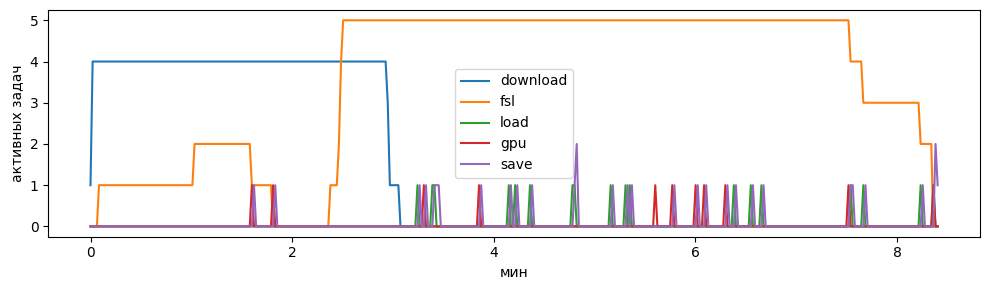

In [29]:
import matplotlib.pyplot as plt
tl = pd.DataFrame(TIMELINE); tl["dur"] = tl.end - tl.start
ok = tl[tl.status == "ok"]
display(ok.groupby("stage").dur.describe()[["count", "mean", "50%", "max"]].round(1))
wall = tl.end.max() - tl.start.min()
gpu_busy = ok[ok.stage == "gpu"].dur.sum()
n_done = ok[ok.stage == "gpu"].shape[0]
print(f"Общее время: {wall/60:.1f} мин; GPU занята {100*gpu_busy/wall:.0f}% времени; "
      f"последовательно было бы ≈ {ok.dur.sum()/60:.0f} мин")
if n_done:
    rate = n_done / wall * 60
    print(f"Пропускная способность ≈ {rate:.1f} испытуемых/мин - 100 испытуемых ≈ {100/rate:.0f} мин, 442 ≈ {442/rate:.0f} мин")

t = np.linspace(tl.start.min(), tl.end.max(), 400)
fig, ax = plt.subplots(figsize=(10, 3))
for st in ["download", "fsl", "load", "gpu", "save"]:
    s = tl[tl.stage == st]
    ax.plot((t - t[0]) / 60, [((s.start <= x) & (s.end >= x)).sum() for x in t], label=st)
ax.set_xlabel("мин"); ax.set_ylabel("активных задач"); ax.legend(); plt.tight_layout()
plt.savefig(OUT / "pipeline_timeline.png", dpi=100); plt.show()

## 12. Визуализация (FLAIR + предсказание + маска)

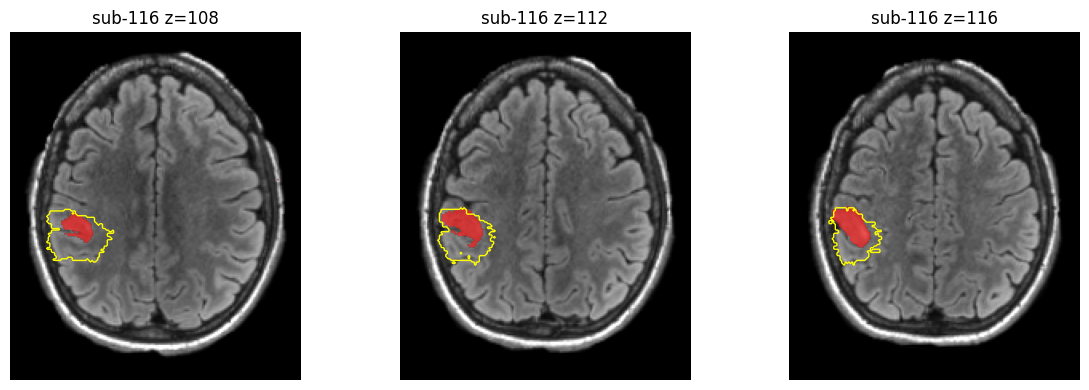

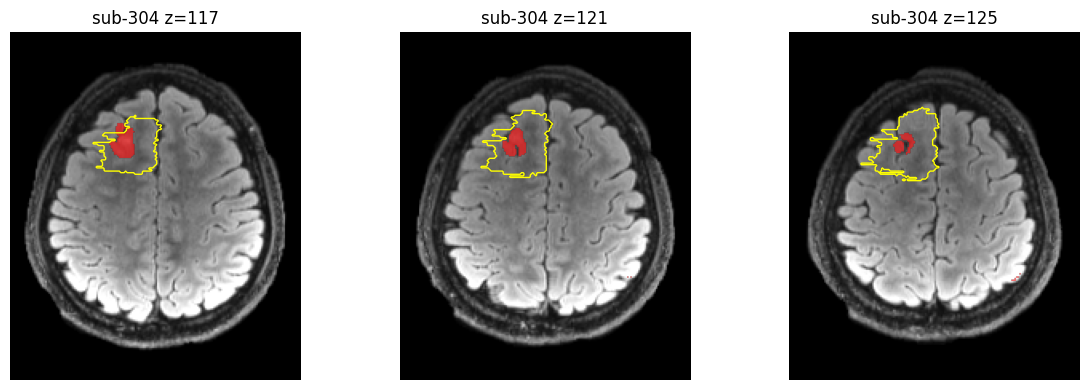

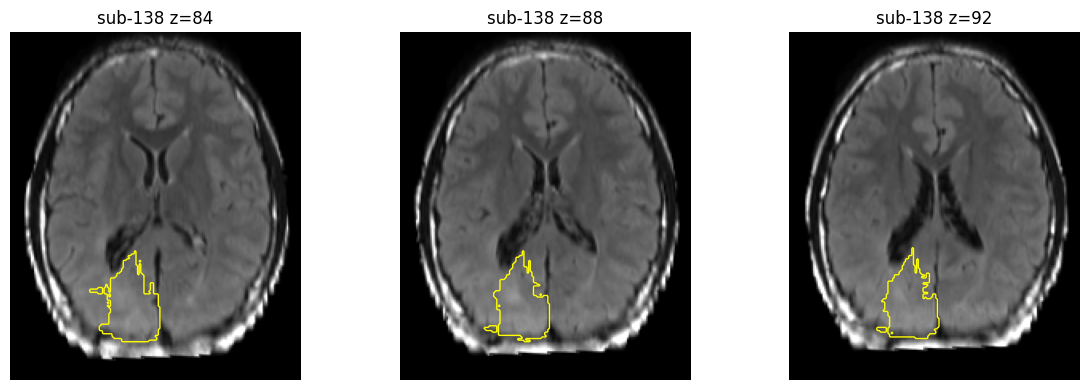

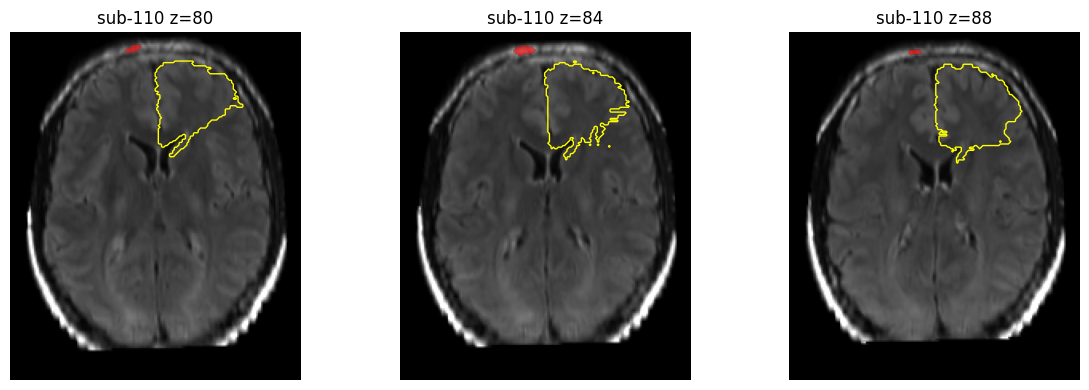

In [30]:
def show(sub, n_slices=3):
    d = WORK / "fsl" / sub
    fl = tf_nolab({"image": [str(d / "t1_reg.nii.gz"), str(d / "flair_reg.nii.gz")]})["image"][1].numpy()
    gt = nib.load(pred_dir / f"{sub}_gt.nii.gz").get_fdata() > 0
    seg = nib.load(pred_dir / f"{sub}_seg.nii.gz").get_fdata() > 0
    zc = int(np.argwhere(gt | seg)[:, 2].mean()) if (gt | seg).any() else fl.shape[2] // 2
    fig, ax = plt.subplots(1, n_slices, figsize=(4 * n_slices, 4))
    for i, z in enumerate(range(zc - 4 * (n_slices // 2), zc + 4 * (n_slices // 2) + 1, 4)):
        ax[i].imshow(np.rot90(fl[:, :, z]), cmap="gray")
        ax[i].contour(np.rot90(gt[:, :, z]), colors="yellow", linewidths=1)
        ax[i].imshow(np.rot90(np.ma.masked_where(~seg[:, :, z], seg[:, :, z])), cmap="autumn", alpha=0.6)
        ax[i].set_title(f"{sub} z={z}"); ax[i].axis("off")
    plt.tight_layout(); plt.savefig(OUT / f"viz_{sub}.png", dpi=100); plt.show()

for sub in m.sort_values("Dice", ascending=False)["sub"].head(2).tolist() + m[m.detected == 0]["sub"].head(2).tolist():
    show(sub)

# 13. Оценка качества MS-DSA-NET на IDEAS

Пациентов с предсказаниями: 25 (исключено по QC: 9); с маской: 25


,IDEAS
n пациентов,25
sSens: ≥1 воксель в маске [95% CI],0.400 [0.23–0.59] (10/25)
Top-1 кластер в маске,0.240
nFPC: среднее [95% CI],18.04 [10.48–27.48]
nFPC: медиана,9
"Пациентов без ложных кластеров, %",0
"Пациентов без предсказаний вообще, %",0
PPV кластеров (верные / все),0.032
Dice: среднее [95% CI],0.043 [0.01–0.09]
Dice: медиана,0.000


Статья (UHB test, n=17): sSens 0.824 | nFPC 0.176 | Dice 0.41 | Sens 0.438 | Prec 0.481

===== По подгруппам (модель обучалась на FCD II) =====


,n,sSens,top1,nFPC,Dice
group,,,,,
FCD IIb,17,0.529,0.294,20.882,0.057
FCD IIa,7,0.143,0.143,12.429,0.015
FCD II,1,0.000,0.000,9.000,0.000


/tmp/ipykernel_614232/729980500.py:133: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: pd.Series({"sSens": d.detected.mean(), "top1": d.top_hit.mean(), "nFPC": d.nFPC.mean(),


,sSens,top1,nFPC,PPV_clusters,Dice,Prec
thr,,,,,,
0.1,0.44,0.24,74.28,0.011,0.048,0.157
0.2,0.40,0.24,46.40,0.014,0.046,0.166
0.3,0.40,0.24,33.16,0.017,0.045,0.170
0.4,0.40,0.24,24.72,0.021,0.044,0.173
0.5,0.40,0.24,18.04,0.032,0.043,0.176
0.6,0.40,0.24,12.32,0.038,0.042,0.177
0.7,0.40,0.24,8.44,0.058,0.040,0.179
0.8,0.36,0.24,5.88,0.070,0.039,0.189
0.9,0.36,0.24,3.96,0.132,0.037,0.193


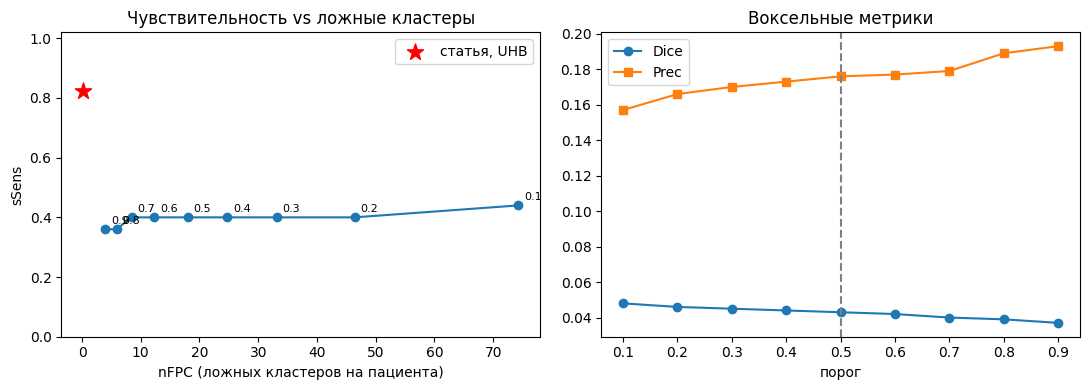

,sub,group,detected,top_hit,n_clusters,nFPC,Dice,Sens,Prec,dist_mm,pred_ml,gt_ml,OP MEMO
0,sub-103,FCD IIa,0,0,3,3,0.000,0.000,0.000,74.793,0.096,95.037,type IIA
1,sub-110,FCD IIb,0,0,15,15,0.000,0.000,0.000,4.123,0.761,135.521,type IIB
2,sub-128,FCD IIa,0,0,13,13,0.000,0.000,0.000,40.853,0.082,18.704,type IIA
3,sub-138,FCD IIa,0,0,2,2,0.000,0.000,0.000,97.642,0.003,106.926,type IIA
4,sub-178,FCD IIb,0,0,6,6,0.000,0.000,0.000,75.604,1.292,40.787,type IIB
5,sub-214,FCD IIb,0,0,8,8,0.000,0.000,0.000,65.727,2.090,8.982,type IIB
6,sub-216,FCD IIb,0,0,88,88,0.000,0.000,0.000,8.000,0.537,35.744,type IIB
7,sub-226,FCD IIb,0,0,7,7,0.000,0.000,0.000,24.597,0.324,21.064,type IIB
8,sub-254,FCD IIa,0,0,11,11,0.000,0.000,0.000,39.862,0.080,144.981,type IIA (MT-Feb18-unusual path; skip lesions ...
9,sub-280,FCD IIb,0,0,11,11,0.000,0.000,0.000,26.981,4.459,30.787,type IIB


Сохранено в /home/trocinskayayv/projects/mri/ms_dsa_net/outputs : eval_summary.csv, eval_per_subject.csv, eval_threshold_sweep.csv, eval_threshold_curves.png


In [31]:
import re
import numpy as np, pandas as pd, nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import ndimage
from concurrent.futures import ThreadPoolExecutor

THR             = 0.5                      # основной порог вероятности (= argmax в оригинальном коде)
SWEEP           = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # пороги для кривой sSens–nFPC
MIN_CLUSTER_VOX = 0                        # отбросить кластеры < N вокселей (1 воксель = 1 мм³); 0 = как в статье
EXCLUDE         = list(globals().get("QC_EXCLUDE", []))   # исключённые по QC регистрации (ячейка 9)
PRED            = Path(globals().get("pred_dir", OUT / "pred"))
STRUCT          = ndimage.generate_binary_structure(3, 3)  # 26-связность, как в статье
PAPER = {"sSens": 0.824, "nFPC": 0.176, "Dice": 0.410, "Sens": 0.438, "Prec": 0.481}   # UHB test, n=17

info = globals().get("SUBJ_INFO")
if info is None:
    _m = pd.read_csv(META_CSV); _m["sub"] = "sub-" + _m["ID"].astype(str)
    info = _m.set_index("sub")[["Pathology", "OP MEMO", "Op_Type"]]

def fcd_subtype(memo):
    t = str(memo)
    m = (re.search(r"(?:FCD|type)\s*(?:type\s*)?(III|II|I|3|2|1)\s*([abcd])?\b", t, re.I)
         or re.search(r"\b(III|II|I)([abcd])\b", t))
    if not m: return "FCD (подтип не указан)"
    roman = {"1": "I", "2": "II", "3": "III"}.get(m.group(1), m.group(1).upper())
    return f"FCD {roman}{(m.group(2) or '').lower()}"

def group_of(row):
    memo, path = row.get("OP MEMO"), row.get("Pathology")
    if path == "FCD" or re.search(r"FCD|dysplas", str(memo), re.I):
        return fcd_subtype(memo) if path == "FCD" else f"{path} + FCD"
    return str(path)

def eval_subject(sub):
    pf, gf = PRED / f"{sub}_prob.nii.gz", PRED / f"{sub}_gt.nii.gz"
    if not pf.exists(): return []
    img = nib.load(pf)
    prob = np.asarray(img.get_fdata(dtype=np.float32))
    zooms = tuple(float(z) for z in img.header.get_zooms()[:3])
    vox_ml = float(np.prod(zooms)) / 1000
    has_gt = gf.exists()
    gt = (np.asarray(nib.load(gf).get_fdata(dtype=np.float32)) > 0.5) if has_gt else np.zeros(prob.shape, bool)

    roi = (prob >= min(SWEEP + [THR])) | gt               
    if roi.any():
        idx = np.argwhere(roi)
        sl = tuple(slice(max(a - 2, 0), b + 3) for a, b in zip(idx.min(0), idx.max(0)))
        prob, gt = prob[sl], gt[sl]
    dist = ndimage.distance_transform_edt(~gt, sampling=zooms) if gt.any() else None

    rows = []
    for t in sorted(set(SWEEP + [THR])):
        seg = prob >= t
        lab, n = ndimage.label(seg, structure=STRUCT)
        if MIN_CLUSTER_VOX and n:
            sizes = ndimage.sum_labels(seg, lab, index=np.arange(1, n + 1))
            seg = np.isin(lab, np.flatnonzero(sizes >= MIN_CLUSTER_VOX) + 1)
            lab, n = ndimage.label(seg, structure=STRUCT)
        r = dict(sub=sub, thr=t, has_gt=has_gt, n_clusters=n,
                 pred_ml=seg.sum() * vox_ml, gt_ml=gt.sum() * vox_ml)
        if has_gt:
            tp_ids = np.unique(lab[gt & (lab > 0)]); tp_ids = tp_ids[tp_ids > 0]
            tp, fp, fn = int((seg & gt).sum()), int((seg & ~gt).sum()), int((~seg & gt).sum())
            r.update(detected=int(len(tp_ids) > 0), n_tp_clusters=len(tp_ids), nFPC=n - len(tp_ids),
                     Dice=2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
                     Sens=tp / (tp + fn) if (tp + fn) else np.nan,
                     Prec=tp / (tp + fp) if (tp + fp) else np.nan)
            if n:
                peaks = np.asarray(ndimage.maximum(prob, lab, index=np.arange(1, n + 1)))
                r["top_hit"] = int((int(np.argmax(peaks)) + 1) in set(tp_ids.tolist()))
                r["dist_mm"] = float(dist[seg].min()) if dist is not None else np.nan
            else:
                r["top_hit"], r["dist_mm"] = 0, np.nan
        rows.append(r)
    return rows

subs = sorted(p.name.replace("_prob.nii.gz", "") for p in PRED.glob("*_prob.nii.gz"))
subs = [s for s in subs if s not in EXCLUDE]
with ThreadPoolExecutor(4) as ex:
    ev = pd.DataFrame([r for rows in ex.map(eval_subject, subs) for r in rows])
ev = ev.join(info, on="sub")
ev["group"] = ev.apply(group_of, axis=1)
print(f"Пациентов с предсказаниями: {len(subs)} (исключено по QC: {len(EXCLUDE)}); "
      f"с маской: {ev[ev.thr == THR].has_gt.sum()}")

def wilson(k, n, z=1.96):
    if n == 0: return np.nan, np.nan
    p, d = k / n, 1 + z * z / n
    c, h = (p + z * z / (2 * n)) / d, z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def boot_ci(x, B=2000, seed=0):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 2: return np.nan, np.nan
    rng = np.random.default_rng(seed)
    return tuple(np.percentile([rng.choice(x, len(x)).mean() for _ in range(B)], [2.5, 97.5]))

def summarize(d):
    n, k = len(d), int(d.detected.sum())
    lo, hi = wilson(k, n); f_lo, f_hi = boot_ci(d.nFPC); d_lo, d_hi = boot_ci(d.Dice)
    tot = d.n_clusters.sum()
    return pd.Series({
        "n пациентов":                                n,
        "sSens: ≥1 воксель в маске [95% CI]":         f"{k/n:.3f} [{lo:.2f}–{hi:.2f}]  ({k}/{n})",
        "Top-1 кластер в маске":                      f"{d.top_hit.mean():.3f}",
        "nFPC: среднее [95% CI]":                     f"{d.nFPC.mean():.2f} [{f_lo:.2f}–{f_hi:.2f}]",
        "nFPC: медиана":                              f"{d.nFPC.median():.0f}",
        "Пациентов без ложных кластеров, %":          f"{100 * (d.nFPC == 0).mean():.0f}",
        "Пациентов без предсказаний вообще, %":       f"{100 * (d.n_clusters == 0).mean():.0f}",
        "PPV кластеров (верные / все)":               f"{d.n_tp_clusters.sum() / tot:.3f}" if tot else "—",
        "Dice: среднее [95% CI]":                     f"{d.Dice.mean():.3f} [{d_lo:.2f}–{d_hi:.2f}]",
        "Dice: медиана":                              f"{d.Dice.median():.3f}",
        "Dice у обнаруженных":                        f"{d.loc[d.detected == 1, 'Dice'].mean():.3f}",
        "Sens (воксели)":                             f"{d.Sens.mean():.3f}",
        "Prec (доля предсказания внутри резекции)":   f"{d.Prec.mean():.3f}",
        "Расстояние до маски у пропущенных, мм (мед.)": f"{d.loc[d.detected == 0, 'dist_mm'].median():.1f}",
        "Объём предсказания, мл (медиана)":           f"{d.pred_ml.median():.1f}",
        "Объём резекции, мл (медиана)":               f"{d.gt_ml.median():.1f}",
    })

main = ev[(ev.thr == THR) & ev.has_gt]
display(summarize(main).to_frame("IDEAS"))
print("Статья (UHB test, n=17): " + " | ".join(f"{k} {v}" for k, v in PAPER.items()))

if main.group.nunique() > 1:
    print("\n===== По подгруппам (модель обучалась на FCD II) =====")
    display(main.groupby("group").agg(n=("sub", "size"), sSens=("detected", "mean"), top1=("top_hit", "mean"),
                                      nFPC=("nFPC", "mean"), Dice=("Dice", "mean")).round(3)
                .sort_values("n", ascending=False))

sw = (ev[ev.has_gt].groupby("thr")
      .apply(lambda d: pd.Series({"sSens": d.detected.mean(), "top1": d.top_hit.mean(), "nFPC": d.nFPC.mean(),
                                  "PPV_clusters": d.n_tp_clusters.sum() / max(d.n_clusters.sum(), 1),
                                  "Dice": d.Dice.mean(), "Prec": d.Prec.mean()}))
      .round(3))
display(sw)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sw.nFPC, sw.sSens, "o-")
for t, r in sw.iterrows(): ax[0].annotate(f"{t:.1f}", (r.nFPC, r.sSens), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[0].scatter([PAPER["nFPC"]], [PAPER["sSens"]], marker="*", s=150, c="red", label="статья, UHB")
ax[0].set_xlabel("nFPC (ложных кластеров на пациента)"); ax[0].set_ylabel("sSens"); ax[0].set_ylim(0, 1.02)
ax[0].set_title("Чувствительность vs ложные кластеры"); ax[0].legend()
ax[1].plot(sw.index, sw.Dice, "o-", label="Dice"); ax[1].plot(sw.index, sw.Prec, "s-", label="Prec")
ax[1].axvline(THR, ls="--", c="grey"); ax[1].set_xlabel("порог"); ax[1].set_title("Воксельные метрики"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "eval_threshold_curves.png", dpi=110); plt.show()

cols = ["sub", "group", "detected", "top_hit", "n_clusters", "nFPC", "Dice", "Sens", "Prec", "dist_mm", "pred_ml", "gt_ml", "OP MEMO"]
per = main[cols].sort_values(["detected", "Dice"], ascending=[True, True]).round(3)
display(per.reset_index(drop=True))

nogt = ev[(ev.thr == THR) & ~ev.has_gt]
if len(nogt):
    print(f"Без маски ({len(nogt)}): кластеров на пациента в среднем {nogt.n_clusters.mean():.2f}")

per.to_csv(OUT / "eval_per_subject.csv", index=False)
summarize(main).to_frame("IDEAS").to_csv(OUT / "eval_summary.csv")
sw.to_csv(OUT / "eval_threshold_sweep.csv")
print("Сохранено в", OUT, ": eval_summary.csv, eval_per_subject.csv, eval_threshold_sweep.csv, eval_threshold_curves.png")